In [ ]:
import pandas as pd
import numpy as np


train = pd.read_csv("../data/raw/train.csv")

meal = pd.read_csv("../data/raw/meal_info.csv")

center = pd.read_csv("../data/raw/fulfilment_center_info.csv")

print("Training Data:")
display(train.head())

print("Meal Information:")
display(meal.head())

print("Fulfilment Center Information:")
display(center.head())

Training Data:


,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders
0,1379560,1,55,1885,136.83,152.29,0,0,177
1,1466964,1,55,1993,136.83,135.83,0,0,270
2,1346989,1,55,2539,134.86,135.86,0,0,189
3,1338232,1,55,2139,339.50,437.53,0,0,54
4,1448490,1,55,2631,243.50,242.50,0,0,40


Meal Information:


,meal_id,category,cuisine
0,1885,Beverages,Thai
1,1993,Beverages,Thai
2,2539,Beverages,Thai
3,1248,Beverages,Indian
4,2631,Beverages,Indian


Fulfilment Center Information:


,center_id,city_code,region_code,center_type,op_area
0,11,679,56,TYPE_A,3.7
1,13,590,56,TYPE_B,6.7
2,124,590,56,TYPE_C,4.0
3,66,648,34,TYPE_A,4.1
4,94,632,34,TYPE_C,3.6


In [10]:
# Dataset Information

print("Training Dataset Shape:", train.shape)
print("Meal Dataset Shape:", meal.shape)
print("Center Dataset Shape:", center.shape)

print("\nTraining Dataset Information:")
train.info()

print("\nMissing Values:")
print(train.isnull().sum())

print("\nStatistical Summary:")
display(train.describe())


Training Dataset Shape: (456548, 9)
Meal Dataset Shape: (51, 3)
Center Dataset Shape: (77, 5)

Training Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 456548 entries, 0 to 456547
Data columns (total 9 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   id                     456548 non-null  int64  
 1   week                   456548 non-null  int64  
 2   center_id              456548 non-null  int64  
 3   meal_id                456548 non-null  int64  
 4   checkout_price         456548 non-null  float64
 5   base_price             456548 non-null  float64
 6   emailer_for_promotion  456548 non-null  int64  
 7   homepage_featured      456548 non-null  int64  
 8   num_orders             456548 non-null  int64  
dtypes: float64(2), int64(7)
memory usage: 31.3 MB

Missing Values:
id                       0
week                     0
center_id                0
meal_id                  0
checko

,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders
count,4.565480e+05,456548.000000,456548.000000,456548.000000,456548.000000,456548.000000,456548.000000,456548.00000,456548.000000
mean,1.250096e+06,74.768771,82.105796,2024.337458,332.238933,354.156627,0.081152,0.10920,261.872760
std,1.443548e+05,41.524956,45.975046,547.420920,152.939723,160.715914,0.273069,0.31189,395.922798
min,1.000000e+06,1.000000,10.000000,1062.000000,2.970000,55.350000,0.000000,0.00000,13.000000
25%,1.124999e+06,39.000000,43.000000,1558.000000,228.950000,243.500000,0.000000,0.00000,54.000000
50%,1.250184e+06,76.000000,76.000000,1993.000000,296.820000,310.460000,0.000000,0.00000,136.000000
75%,1.375140e+06,111.000000,110.000000,2539.000000,445.230000,458.870000,0.000000,0.00000,324.000000
max,1.499999e+06,145.000000,186.000000,2956.000000,866.270000,866.270000,1.000000,1.00000,24299.000000


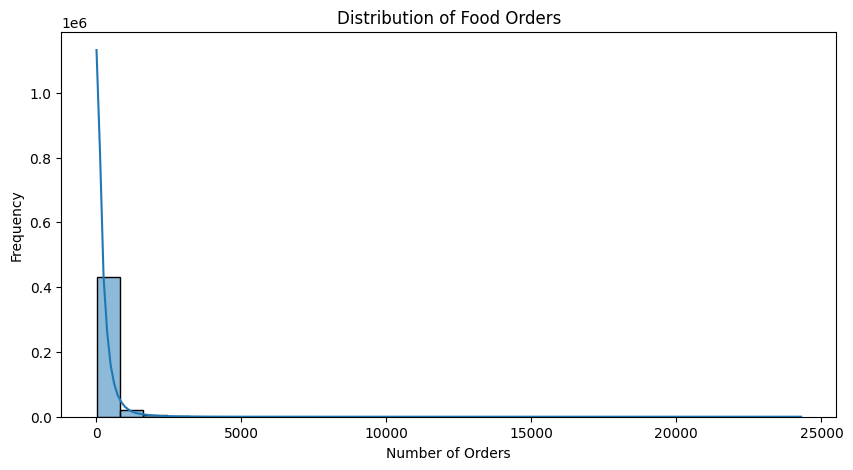

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(train['num_orders'], bins=30, kde=True)

plt.title("Distribution of Food Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Frequency")

plt.show()


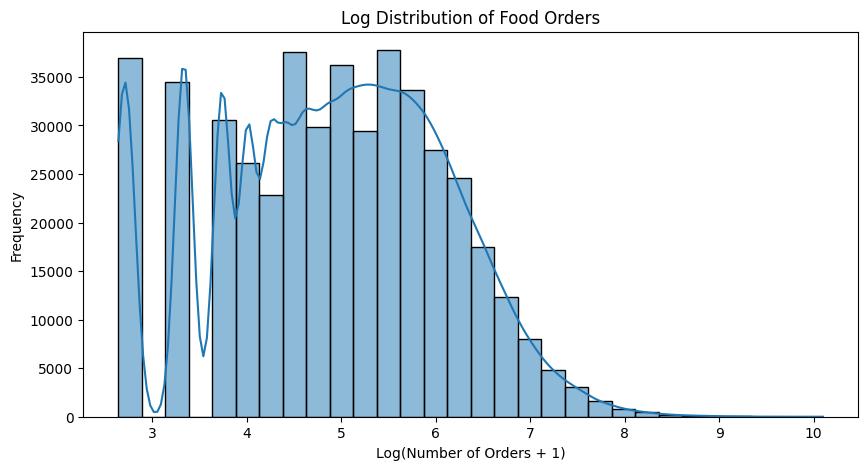

In [11]:
# Log Transformation of Number of Orders

plt.figure(figsize=(10, 5))

sns.histplot(
    np.log1p(train['num_orders']),
    bins=30,
    kde=True
)

plt.title("Log Distribution of Food Orders")
plt.xlabel("Log(Number of Orders + 1)")
plt.ylabel("Frequency")

plt.show()

## Key Observations

1. The training dataset contains 456,548 records.
2. The dataset contains information about food orders,
   meals, and fulfilment centers.
3. The distribution of food orders is right-skewed.
4. Log transformation helps visualize the distribution
   across a wider range of order values.

## Conclusion

Exploratory Data Analysis helps understand the food
demand patterns and prepares the dataset for
machine learning model development.

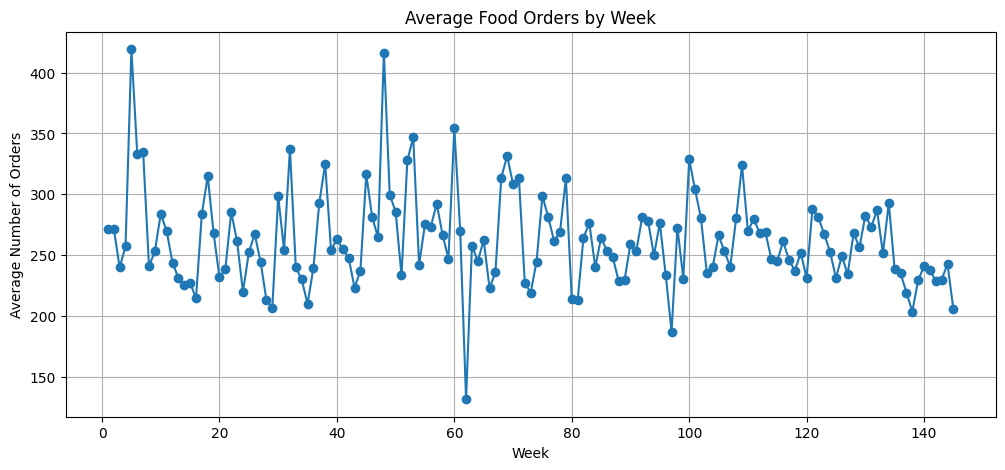

In [12]:
# Average Orders by Week

weekly_orders = train.groupby('week')['num_orders'].mean()

plt.figure(figsize=(12, 5))

plt.plot(
    weekly_orders.index,
    weekly_orders.values,
    marker='o'
)

plt.title("Average Food Orders by Week")
plt.xlabel("Week")
plt.ylabel("Average Number of Orders")
plt.grid(True)

plt.show()

## Weekly Food Demand Analysis

This visualization shows how average food orders
change across different weeks.

It helps identify:
- Changes in food demand over time.
- Potential seasonal patterns.
- Periods of higher and lower demand.

This analysis can help improve food demand forecasting
and reduce unnecessary food waste.

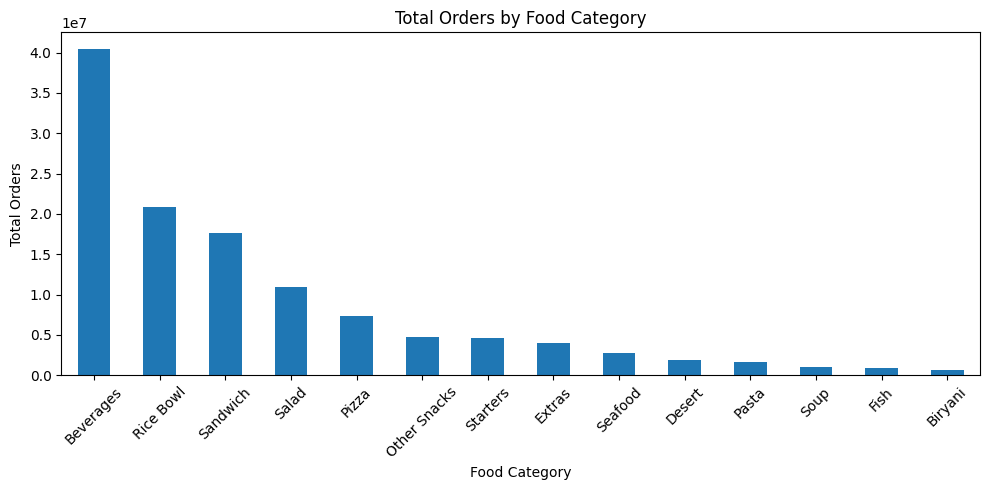

In [13]:
# Food Category Analysis

food_data = train.merge(
    meal,
    on='meal_id',
    how='left'
)

category_orders = food_data.groupby(
    'category'
)['num_orders'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))

category_orders.plot(kind='bar')

plt.title("Total Orders by Food Category")
plt.xlabel("Food Category")
plt.ylabel("Total Orders")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Final Conclusion

The exploratory data analysis provides useful insights
into food demand patterns.

Key findings:

1. The training dataset contains 456,548 records.
2. Food order distribution is right-skewed.
3. Log transformation helps visualize order distribution.
4. Weekly analysis helps understand changes in demand.
5. Food category analysis identifies popular meal categories.

These insights can support better food demand prediction,
inventory planning, and reduction of food waste.

## Next Steps

- Data preprocessing
- Feature engineering
- Machine learning model training
- Model evaluation
- Food waste prediction